# InternCircle Task 4 – First Machine Learning Classifier

## Objective

To build and evaluate a Machine Learning classification model using Python and Scikit-Learn.

In this task, the Titanic dataset is used to predict whether a passenger survived or did not survive.

A Decision Tree Classifier is trained using selected passenger features. The dataset is divided into training and testing sets, and the model is evaluated using accuracy, confusion matrix, and Mean Squared Error (MSE).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the Dataset

The Titanic dataset is loaded using Seaborn. The dataset contains information about passengers such as passenger class, age, gender, family members, fare, and survival status.

In [2]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (891, 15)


## 2. Exploring the Dataset

The first few records are displayed to understand the available features and target variable.

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Selecting Features and Target

The target variable is `survived`.

- 0 represents passengers who did not survive.
- 1 represents passengers who survived.

The selected features are passenger class, gender, age, number of siblings/spouses, number of parents/children, and fare.

In [5]:
features = ["pclass", "sex", "age", "sibsp", "parch", "fare"]

X = df[features].copy()
y = df["survived"]

print("Features selected:")
print(features)

print("\nTarget variable: survived")

Features selected:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']

Target variable: survived


## 4. Data Preprocessing

Machine Learning models require numerical input values.

The categorical `sex` column is converted into numerical values:

- Female = 0
- Male = 1

Missing age values are replaced using the median age.

In [6]:
X["sex"] = X["sex"].map({"female": 0, "male": 1})

X["age"] = X["age"].fillna(X["age"].median())

print("Missing values after preprocessing:")
print(X.isnull().sum())

Missing values after preprocessing:
pclass    0
sex       0
age       0
sibsp     0
parch     0
fare      0
dtype: int64


## 5. Splitting the Dataset

The dataset is divided into training and testing sets.

- 80% of the data is used for training.
- 20% of the data is used for testing.

The `random_state` value ensures reproducible results.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 712
Testing samples: 179


## 6. Creating the Decision Tree Classifier

A Decision Tree Classifier is used to predict whether a passenger survived.

The model learns decision rules from the training data and uses those rules to classify unseen passengers.

In [8]:
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

print("Decision Tree Classifier created successfully!")

Decision Tree Classifier created successfully!


## 7. Training the Machine Learning Model

The Decision Tree Classifier is trained using the training dataset.

In [9]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


## 8. Making Predictions

The trained model is used to predict the survival status of passengers in the test dataset.

In [10]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!
First 10 predictions:
[0 0 0 0 0 0 1 1 0 0]


## 9. Model Accuracy

Accuracy is calculated to measure the percentage of test observations correctly classified by the model.

In [11]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy, 4))
print("Model Accuracy (%):", round(accuracy * 100, 2), "%")

Model Accuracy: 0.7542
Model Accuracy (%): 75.42 %


## 10. Confusion Matrix

A confusion matrix is used to evaluate the classification performance of the model.

It shows:

- True Negative
- False Positive
- False Negative
- True Positive

In [12]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[97 13]
 [31 38]]


## 11. Confusion Matrix Visualization

The confusion matrix is visualized using a Seaborn heatmap for easier interpretation.

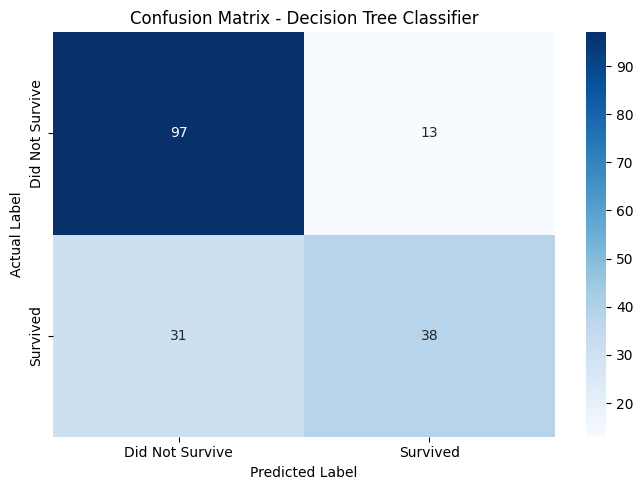

In [13]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.title("Confusion Matrix - Decision Tree Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## 12. Mean Squared Error

Mean Squared Error (MSE) is calculated by comparing the actual survival values with the predicted values.

Although MSE is mainly used for regression problems, it can also be calculated here as an additional evaluation metric because the classification target is represented using 0 and 1.

In [14]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", round(mse, 4))

Mean Squared Error: 0.2458


## 13. Classification Report

The classification report provides precision, recall, and F1-score for the two classes.

In [15]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.88      0.82       110
           1       0.75      0.55      0.63        69

    accuracy                           0.75       179
   macro avg       0.75      0.72      0.72       179
weighted avg       0.75      0.75      0.75       179



## 14. Feature Importance

The Decision Tree model provides feature importance values that indicate how much each feature contributes to the model's predictions.

In [16]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance.round(4))

Feature Importance:
sex       0.5344
pclass    0.1817
fare      0.1372
age       0.1196
parch     0.0159
sibsp     0.0112
dtype: float64


## 15. Feature Importance Visualization

A bar chart is created to visualize the importance of each feature used by the Decision Tree model.

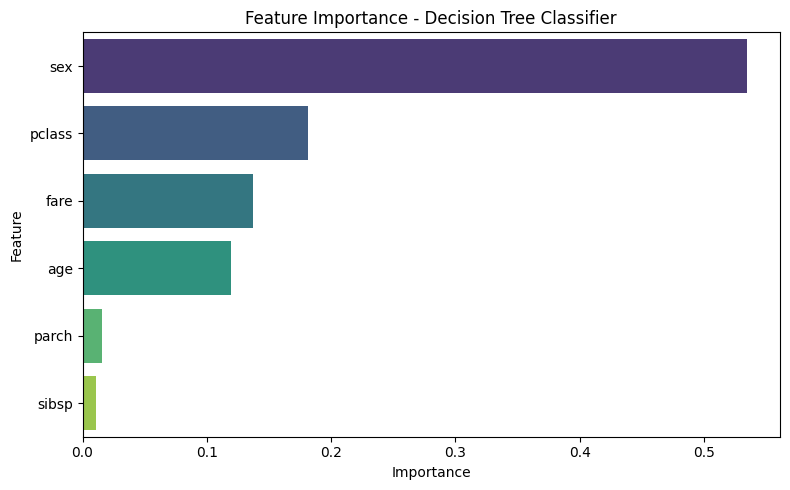

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index,
    hue=feature_importance.index,
    palette="viridis",
    legend=False
)

plt.title("Feature Importance - Decision Tree Classifier")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 16. Key Machine Learning Findings

1. A Decision Tree Classifier was successfully trained using the Titanic dataset.

2. The dataset was divided into training and testing sets using an 80:20 ratio.

3. The model predicts whether a passenger survived based on selected passenger characteristics.

4. Model accuracy was calculated using the test dataset.

5. A confusion matrix was used to analyze correct and incorrect predictions.

6. Mean Squared Error was calculated as an additional evaluation metric.

7. Feature importance analysis was used to identify the contribution of different features to the model.

8. The project demonstrates the basic workflow of a supervised Machine Learning classification problem.

## 17. Conclusion

A Decision Tree Classification model was successfully developed using Python and Scikit-Learn.

The Titanic dataset was preprocessed, divided into training and testing sets, and used to train the classification model.

The model was evaluated using accuracy, confusion matrix, Mean Squared Error, and classification metrics.

Feature importance was also analyzed to understand the contribution of different input variables.

This task provided practical experience in data preprocessing, train-test splitting, model training, prediction, and Machine Learning model evaluation.